# SI 671 — 07 Enhanced Network Ablation (Validation Only)

**RQ3:** Does historical NYC Yellow Taxi OD-network information add predictive value beyond a stronger temporal model?

**Design.** Reproduce the canonical dataset and time rules from `05_forecasting_revised.ipynb` and `06_forecasting_model_diagnostics.ipynb`. Compare **M1′–M4′** using a *shared* training/validation sample, **Poisson LightGBM**, **6000 boosting-round cap**, and consistent early stopping on **L1 / MAE**.

- **Train:** 2025-01 through 2025-08; **Validation:** 2025-09 through 2025-10.
- **No Nov–Dec test-set evaluation or tuning** in this notebook.
- **One-hour-ahead rolling forecast:** each target hour uses lagged local pickups and historical OD features available before that hour, subject to the source's historical-data availability assumptions.
- **Primary comparison:** paired validation MAE differences M1′→M2′→M3′→M4′.
- **Outputs:** `results/forecasting/enhanced_network_ablation/` only; the final models and test results from notebook 05 remain untouched.

**Context:** Notebook 06 found that Original + Short-term Dynamics with Poisson and a 6000-round cap achieved the lowest validation MAE among its evaluated configurations. This notebook tests whether network features add value *on top of that configuration*. It does not use this validation set as an independent confirmatory test of prior decisions.

## 0 — Configuration, input checks, reproducibility

Use the **`si671-urban`** kernel and run from `Urban_Mobility_Mining/` or its `notebooks/` directory. `SMOKE_TEST=True` is only a quick pipeline check and should not be reported as a modeling result.

In [1]:
from pathlib import Path
import json, platform, sys, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "data" / "processed" / "cleaned_trips").is_dir(), (
    f"Open the notebook from repository root or notebooks/: {PROJECT_ROOT}"
)
CLEAN_DIR = PROJECT_ROOT / "data/processed/cleaned_trips"
ZONE_FILE = PROJECT_ROOT / "data/external/taxi_zone_lookup.csv"
AUG_FILE = PROJECT_ROOT / "data/processed/network_features/historical_network_features_24h_augmented.parquet"
ORIGINAL_FILE = PROJECT_ROOT / "data/processed/network_features/historical_network_features_24h.parquet"
OUT = PROJECT_ROOT / "results/forecasting/enhanced_network_ablation"
OUT.mkdir(parents=True, exist_ok=True)
SMOKE_TEST = False  # True: quick run only; do NOT interpret/reproduce final statistics
MAX_ROUNDS = 200 if SMOKE_TEST else 6000
EARLY_STOPPING_ROUNDS = 30 if SMOKE_TEST else 200
SAVE_MODELS = False  # large artifacts; set True if you explicitly want 4 .joblib files
NUM_THREADS = 4  # lower this if your Mac runs out of RAM
RANDOM_SEED = 671
TRAIN_END = pd.Timestamp("2025-09-01")
VAL_END = pd.Timestamp("2025-11-01")
START, END = pd.Timestamp("2025-01-01"), pd.Timestamp("2026-01-01")
TARGET = "pickup_count"
for path in [ZONE_FILE, AUG_FILE]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing required input: {path}")
monthly_paths = [CLEAN_DIR / f"cleaned_2025-{m:02d}.parquet" for m in range(1,13)]
assert all(p.is_file() for p in monthly_paths), "All 12 cleaned_2025-MM.parquet files are required"
print("Root:", PROJECT_ROOT)
print("Kernel:", sys.executable)
print("Python/pandas/LightGBM:", platform.python_version(), pd.__version__, lgb.__version__)
print("Run type:", "SMOKE TEST (not final)" if SMOKE_TEST else "FULL VALIDATION DIAGNOSTICS")
print("Output folder:", OUT)
print("Boosting cap:", MAX_ROUNDS)

Root: /Users/wushixundelaopo/Desktop/Urban_Mobility_Mining
Kernel: /opt/anaconda3/envs/si671-urban/bin/python
Python/pandas/LightGBM: 3.11.18 3.1.0 4.7.0
Run type: FULL VALIDATION DIAGNOSTICS
Output folder: /Users/wushixundelaopo/Desktop/Urban_Mobility_Mining/results/forecasting/enhanced_network_ablation
Boosting cap: 6000


## 1 — Rebuild 2025 zone-hour pickup panel

Exactly the same filtering and 263-zone balanced-panel procedure as notebook 06, so comparison to notebook 06 is meaningful.

In [2]:
zone_lookup = pd.read_csv(ZONE_FILE)
assert "LocationID" in zone_lookup.columns
forecast_zone_ids = sorted(set(zone_lookup["LocationID"].dropna().astype(int)) - {264, 265})
assert len(forecast_zone_ids) == 263, f"Expected 263 zone IDs; got {len(forecast_zone_ids)}"
monthly_panels, source_report = [], []
for month, path in enumerate(monthly_paths, start=1):
    trips = pd.read_parquet(path, columns=["tpep_pickup_datetime", "PULocationID"])
    raw_rows = len(trips)
    month_start = pd.Timestamp(2025, month, 1)
    month_end = month_start + pd.DateOffset(months=1)
    trips = trips.loc[trips["PULocationID"].isin(forecast_zone_ids)].copy()
    times = pd.to_datetime(trips["tpep_pickup_datetime"])
    out_of_month = int(((times < month_start) | (times >= month_end) | times.isna()).sum())
    if out_of_month:
        raise ValueError(f"{path.name}: {out_of_month:,} pickup timestamps outside month; check cleaning source")
    trips["pickup_hour"] = times.dt.floor("h")
    grouped = trips.groupby(["PULocationID", "pickup_hour"], observed=True).size()
    hours = pd.date_range(month_start, month_end, freq="h", inclusive="left")
    keys = pd.MultiIndex.from_product([forecast_zone_ids, hours], names=["PULocationID", "pickup_hour"])
    panel = grouped.reindex(keys, fill_value=0).rename("pickup_count").reset_index()
    panel = panel.rename(columns={"PULocationID": "zone_id"})
    panel["pickup_count"] = panel["pickup_count"].astype("int32")
    assert panel["pickup_count"].sum() == len(trips)
    assert len(panel) == len(forecast_zone_ids)*len(hours)
    monthly_panels.append(panel)
    source_report.append({"month":month_start.strftime("%Y-%m"), "file_rows":raw_rows,
                          "geographic_pickups":len(trips), "zone_hours":len(panel), "hours":len(hours)})
    del trips, panel, grouped, keys

full_year_panel = (pd.concat(monthly_panels, ignore_index=True)
                   .sort_values(["zone_id", "pickup_hour"]).reset_index(drop=True))
del monthly_panels
expected_hours = len(pd.date_range(START, END, freq="h", inclusive="left"))
assert len(full_year_panel) == len(forecast_zone_ids)*expected_hours
assert full_year_panel[["zone_id", "pickup_hour"]].notna().all().all()
assert not full_year_panel.duplicated(["zone_id", "pickup_hour"]).any()
assert full_year_panel["pickup_count"].ge(0).all()
assert full_year_panel["pickup_count"].sum() == sum(x["geographic_pickups"] for x in source_report)
print(f"2025 panel: {len(full_year_panel):,} zone-hours; {expected_hours:,} nominal wall-clock hours")
print("Zero-demand fraction:", round(full_year_panel[TARGET].eq(0).mean(), 4))
display(pd.DataFrame(source_report))

2025 panel: 2,303,880 zone-hours; 8,760 nominal wall-clock hours
Zero-demand fraction: 0.3858


,month,file_rows,geographic_pickups,zone_hours,hours
0,2025-01,3475204,3465683,195672,744
1,2025-02,3577512,3568877,176736,672
2,2025-03,4145224,4135989,195672,744
3,2025-04,3970546,3961555,189360,720
4,2025-05,4591821,4582134,195672,744
5,2025-06,4322940,4314345,189360,720
6,2025-07,3898956,3890590,195672,744
7,2025-08,3574074,3566467,195672,744
8,2025-09,4251008,4242793,189360,720
9,2025-10,4428686,4420144,195672,744


## 2 — Historical temporal features and DST exclusion

The `shift(1)` operation excludes current-hour pickup counts from every rolling feature. DST-affected target hours (and up to 168 hours of subsequent history) are conservatively excluded as in notebooks 05/06. The fixed 2025 row-count assertion helps detect accidental changes to the source or logic; adjust it only after investigating a legitimate data update.

In [3]:
forecast_df = full_year_panel.copy()  # already zone/time sorted
series = forecast_df.groupby("zone_id", sort=False, observed=True)[TARGET]
for lag in [1, 2, 3, 24, 48, 168]:
    forecast_df[f"lag_{lag}"] = series.shift(lag).astype("float32")
for window in [3, 6, 24, 168]:
    forecast_df[f"rolling_mean_{window}"] = series.transform(
        lambda x: x.shift(1).rolling(window, min_periods=window).mean()
    ).astype("float32")
forecast_df["rolling_std_24"] = series.transform(
    lambda x: x.shift(1).rolling(24, min_periods=24).std()
).astype("float32")
forecast_df["trend_3_vs_24"] = (
    forecast_df["rolling_mean_3"] - forecast_df["rolling_mean_24"]
).astype("float32")
t = forecast_df["pickup_hour"]
forecast_df["hour"] = t.dt.hour.astype("int8")
forecast_df["day_of_week"] = t.dt.dayofweek.astype("int8")
forecast_df["is_weekend"] = (t.dt.dayofweek >= 5).astype("int8")
forecast_df["month"] = t.dt.month.astype("int8")
forecast_df["hour_sin"] = np.sin(2*np.pi*t.dt.hour/24).astype("float32")
forecast_df["hour_cos"] = np.cos(2*np.pi*t.dt.hour/24).astype("float32")

DST_BAD_HOURS = [pd.Timestamp("2025-03-09 02:00:00"), pd.Timestamp("2025-11-02 01:00:00")]
forecast_df["dst_history_affected"] = False
for h in DST_BAD_HOURS:
    forecast_df.loc[forecast_df["pickup_hour"].between(h, h+pd.Timedelta(hours=168)),
                    "dst_history_affected"] = True

ORIGINAL_TEMPORAL = ["lag_1", "lag_24", "lag_168", "rolling_mean_24", "rolling_mean_168",
                     "hour", "day_of_week", "is_weekend", "zone_id"]
ENHANCED_EXTRA = ["lag_2", "lag_3", "lag_48", "rolling_mean_3", "rolling_mean_6",
                  "rolling_std_24", "trend_3_vs_24", "month", "hour_sin", "hour_cos"]
ENHANCED_TEMPORAL = ORIGINAL_TEMPORAL + ENHANCED_EXTRA

# Validate history on representative zones and times, including around DST-adjacent periods.
for zone, dt in [(161, "2025-06-10 15:00"), (43, "2025-09-15 10:00")]:
    hit = forecast_df.loc[(forecast_df.zone_id == zone) &
                          (forecast_df.pickup_hour == pd.Timestamp(dt))].iloc[0]
    past = full_year_panel.loc[(full_year_panel.zone_id == zone) &
                               (full_year_panel.pickup_hour < pd.Timestamp(dt))].sort_values("pickup_hour")
    assert np.isclose(hit["lag_1"], past[TARGET].iloc[-1])
    assert np.isclose(hit["rolling_mean_24"], past[TARGET].iloc[-24:].mean())
    assert np.isclose(hit["rolling_mean_3"], past[TARGET].iloc[-3:].mean())

model_df = forecast_df.loc[~forecast_df["dst_history_affected"]].dropna(
    subset=ENHANCED_TEMPORAL + [TARGET]
).copy().sort_values(["pickup_hour", "zone_id"]).reset_index(drop=True)
assert not model_df.duplicated(["zone_id", "pickup_hour"]).any()
assert not model_df["dst_history_affected"].fillna(True).any()
assert model_df[ENHANCED_TEMPORAL + [TARGET]].notna().all().all()
assert model_df[TARGET].ge(0).all()
print("Modeling rows after historical-coverage and DST exclusion:", f"{len(model_df):,}")
print("DST-affected model rows:", int(model_df.dst_history_affected.sum()))
assert len(model_df) == 2_170_802, "Unexpected count relative to prior 2025 pipeline; investigate before fitting"

/var/folders/ww/5mshxs8524ngyq_y2qdc9t9c0000gn/T/ipykernel_93020/2243468088.py:17: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  forecast_df["day_of_week"] = t.dt.dayofweek.astype("int8")
/var/folders/ww/5mshxs8524ngyq_y2qdc9t9c0000gn/T/ipykernel_93020/2243468088.py:18: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  forecast_df["is_weekend"] = (t.dt.dayofweek >= 5).astype("int8")


Modeling rows after historical-coverage and DST exclusion: 2,170,802
DST-affected model rows: 0


## 3 — Load augmented OD features and verify the common sample

Degree is defined even for zero-flow periods. HHI is undefined (NaN) if there is no interzone flow; **keep NaN** for LightGBM rather than inventing a concentration of zero. The two flow-availability flags are included with the HHI feature block.

In [4]:
STRENGTH = ["in_strength_24h", "out_strength_24h",
            "interzone_in_strength_24h", "interzone_out_strength_24h"]
DEGREE = ["in_degree_24h", "out_degree_24h"]
HHI = ["in_hhi_24h", "out_hhi_24h"]
FLOW_FLAGS = ["has_interzone_in_flow_24h", "has_interzone_out_flow_24h"]
KEY_LEFT, KEY_NET = ["zone_id", "pickup_hour"], ["zone_id", "feature_as_of"]
net = pd.read_parquet(AUG_FILE)
required = set(KEY_NET + STRENGTH + DEGREE + HHI + FLOW_FLAGS +
               ["has_full_history_24h", "dst_safe_24h"])
assert required.issubset(net.columns), f"Missing augmented feature fields: {required - set(net.columns)}"
net["zone_id"] = net["zone_id"].astype("int32")
net["feature_as_of"] = pd.to_datetime(net["feature_as_of"])
assert not net.duplicated(KEY_NET).any()
assert net["zone_id"].nunique() == len(forecast_zone_ids)

model_df["zone_id"] = model_df["zone_id"].astype("int32")
model_df["pickup_hour"] = pd.to_datetime(model_df["pickup_hour"])
merged = model_df.merge(net, how="left", left_on=KEY_LEFT, right_on=KEY_NET,
                        validate="one_to_one", indicator=True)
assert len(merged) == len(model_df)
assert merged["_merge"].eq("both").all(), "Some forecast zone-hours failed to join"
assert merged["pickup_hour"].eq(merged["feature_as_of"]).all()
valid_network = (merged["has_full_history_24h"].fillna(False).astype(bool)
                 & merged["dst_safe_24h"].fillna(False).astype(bool)
                 & ~merged["dst_history_affected"].fillna(True).astype(bool))
canonical_df = merged.loc[valid_network].drop(columns=["_merge"]).copy()
del merged
assert not canonical_df.empty
assert not canonical_df.duplicated(KEY_LEFT).any()
assert canonical_df[STRENGTH + DEGREE].notna().all().all()
for direction in ["in", "out"]:
    miss = canonical_df[f"{direction}_hhi_24h"].isna()
    has_flow = canonical_df[f"has_interzone_{direction}_flow_24h"].astype(bool)
    assert (miss == ~has_flow).all(), f"HHI/flow-availability mismatch: {direction}"
    assert canonical_df.loc[~miss, f"{direction}_hhi_24h"].between(0, 1).all()
    assert canonical_df[f"{direction}_degree_24h"].ge(0).all()

# Compare old strength-only file with augmented table, when provided.
if ORIGINAL_FILE.exists():
    original = pd.read_parquet(ORIGINAL_FILE, columns=KEY_NET + STRENGTH)
    original["feature_as_of"] = pd.to_datetime(original["feature_as_of"])
    a = original.sort_values(KEY_NET).reset_index(drop=True)
    b = net[KEY_NET + STRENGTH].sort_values(KEY_NET).reset_index(drop=True)
    pd.testing.assert_frame_equal(a[KEY_NET], b[KEY_NET], check_dtype=False)
    pd.testing.assert_frame_equal(a[STRENGTH], b[STRENGTH], check_dtype=False)
    del original, a, b
    print("PASS: original and augmented strength tables are key/value identical")
else:
    print("Original strength-only parquet absent: cross-version comparison skipped")

print("Merged common sample:", f"{len(canonical_df):,}", "of", f"{len(model_df):,}")
print("Undefined in/out HHI:", *(f"{canonical_df[x].isna().sum():,}" for x in HHI))

PASS: original and augmented strength tables are key/value identical
Merged common sample: 2,170,802 of 2,170,802
Undefined in/out HHI: 103,738 195,447


## 4 — Chronological Train / Validation split

All four models use *identical row keys, target values and missingness policy*. The November–December period is present in the original yearly panel only to maintain the same source construction; it is never used for training or evaluating models in this notebook.

In [5]:
# Train / Validation only: test data must not enter model selection
canonical_df = canonical_df.sort_values(["pickup_hour", "zone_id"]).reset_index(drop=True)
train = canonical_df.loc[canonical_df["pickup_hour"] < TRAIN_END].copy()
val = canonical_df.loc[(canonical_df["pickup_hour"] >= TRAIN_END) &
                       (canonical_df["pickup_hour"] < VAL_END)].copy()
assert len(train) == 1_445_185 and len(val) == 385_032, (
    f"Unexpected split sizes: {len(train):,}, {len(val):,}"
)
assert train["pickup_hour"].max() < val["pickup_hour"].min()
assert not train.duplicated(["zone_id", "pickup_hour"]).any()
assert not val.duplicated(["zone_id", "pickup_hour"]).any()
zone_dtype = pd.CategoricalDtype(categories=forecast_zone_ids, ordered=False)
for d in (train, val):
    d["zone_id"] = d["zone_id"].astype(zone_dtype)
    assert d[ENHANCED_TEMPORAL + [TARGET]].notna().all().all()
print(f"Train: {len(train):,} | Validation: {len(val):,}")
print("Training ends:", train.pickup_hour.max(), "| Validation starts:", val.pickup_hour.min())
# Save only a lightweight manifest, never overwrite existing final_rq3/ files.

Train: 1,445,185 | Validation: 385,032
Training ends: 2025-08-31 23:00:00 | Validation starts: 2025-09-01 00:00:00


## 5 — Register M1′–M4′ feature sets and shared model configuration

**M1′:** Original temporal + five short-term dynamics features. **M2′:** M1′ + four OD strengths. **M3′:** M2′ + in/out degree. **M4′:** M3′ + in/out HHI **and** two flow flags (one combined feature block, not HHI-only). Model and target are held constant so each step isolates the *incremental feature block* under the same algorithm and training budget.

Note: earlier 6000-round models were still near the cap. This experiment **does not claim convergence is reached**, and it avoids expanding the search again without a new experiment plan.

In [6]:
from time import perf_counter

SHORT_TERM = ["lag_2", "lag_3", "rolling_mean_3", "rolling_mean_6", "trend_3_vs_24"]
TEMPORAL_07 = list(ORIGINAL_TEMPORAL) + SHORT_TERM
FEATURE_SETS = {
    "M1 Enhanced Temporal": TEMPORAL_07,
    "M2 + OD Strength": TEMPORAL_07 + STRENGTH,
    "M3 + Degree": TEMPORAL_07 + STRENGTH + DEGREE,
    "M4 + HHI & Flow Flags": TEMPORAL_07 + STRENGTH + DEGREE + HHI + FLOW_FLAGS,
}
MODEL_NAMES = list(FEATURE_SETS)

COMMON_PARAMS = {
    "objective": "poisson",
    "metric": "l1",
    "n_estimators": MAX_ROUNDS,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "min_child_samples": 20,
    "random_state": RANDOM_SEED,
    "n_jobs": NUM_THREADS,
    "verbosity": -1,
}
for label, cols in FEATURE_SETS.items():
    assert len(cols) == len(set(cols)), f"Duplicate features: {label}"
    assert set(cols).issubset(train.columns) and set(cols).issubset(val.columns)
    assert train[[c for c in cols if c not in HHI]].notna().all().all()
    assert val[[c for c in cols if c not in HHI]].notna().all().all()
assert train[TARGET].ge(0).all() and val[TARGET].ge(0).all()
assert len(set(TEMPORAL_07) & set(STRENGTH + DEGREE + HHI + FLOW_FLAGS)) == 0
print(pd.DataFrame([{
    "model": name, "n_features": len(cols),
    "incremental_features": ", ".join(cols if i == 0 else [c for c in cols if c not in FEATURE_SETS[MODEL_NAMES[i-1]]])
} for i, (name, cols) in enumerate(FEATURE_SETS.items())]).to_string(index=False))
print("Parameters:", COMMON_PARAMS)

                model  n_features                                                                                                                                           incremental_features
 M1 Enhanced Temporal          14 lag_1, lag_24, lag_168, rolling_mean_24, rolling_mean_168, hour, day_of_week, is_weekend, zone_id, lag_2, lag_3, rolling_mean_3, rolling_mean_6, trend_3_vs_24
     M2 + OD Strength          18                                                                       in_strength_24h, out_strength_24h, interzone_in_strength_24h, interzone_out_strength_24h
          M3 + Degree          20                                                                                                                                  in_degree_24h, out_degree_24h
M4 + HHI & Flow Flags          24                                                                                 in_hhi_24h, out_hhi_24h, has_interzone_in_flow_24h, has_interzone_out_flow_24h
Parameters: {'objective': 'poisson'

## 6 — Train four Poisson LightGBM models (Validation only)

- For each model, validation **L1** is the sole metric used for early stopping.
- Store out-of-sample validation predictions in the same original `val` row order.
- Save exact trained iteration counts and learning histories; do not use `Test` here.
- Poisson predictions are nonnegative, so no clipping is needed.

On an M-series Mac, 6000 rounds × four models can take substantial time. Training runs **sequentially** with four threads; reduce `NUM_THREADS` if necessary.

In [7]:
import gc

y_val = val[TARGET].to_numpy(dtype=np.float64)
base_columns = ["zone_id", "pickup_hour", TARGET]
validation_predictions_df = val[base_columns].copy().reset_index(drop=True)
results = []
learning_histories = {}
feature_importances = []
trained_models = {} if SAVE_MODELS else None

for idx, (name, cols) in enumerate(FEATURE_SETS.items(), start=1):
    print(f"\n[{idx}/4] Training {name} ({len(cols)} features)", flush=True)
    start_time = perf_counter()
    model = lgb.LGBMRegressor(**COMMON_PARAMS)
    history = {}
    model.fit(
        train[cols], train[TARGET],
        eval_set=[(val[cols], val[TARGET])],
        eval_metric="l1",
        categorical_feature=["zone_id"],
        callbacks=[
            lgb.early_stopping(EARLY_STOPPING_ROUNDS, first_metric_only=True, verbose=False),
            lgb.record_evaluation(history),
            lgb.log_evaluation(1000),
        ],
    )
    pred = np.asarray(model.predict(val[cols], num_iteration=model.best_iteration_), dtype=np.float64)
    assert len(pred) == len(y_val)
    assert np.isfinite(pred).all() and (pred >= 0).all()
    code_name = name.split()[0].lower()
    validation_predictions_df[f"pred_{code_name}"] = pred
    mae = float(np.abs(y_val-pred).mean())
    rmse = float(np.sqrt(np.mean((y_val-pred)**2)))
    best_iteration = int(model.best_iteration_ or MAX_ROUNDS)
    results.append({
        "model": name, "code": code_name, "n_features": len(cols),
        "train_rows": len(train), "validation_rows": len(val),
        "max_rounds": MAX_ROUNDS, "best_iteration": best_iteration,
        "near_round_cap": best_iteration >= MAX_ROUNDS - 10,
        "val_mae": mae, "val_rmse": rmse,
        "training_seconds": round(perf_counter() - start_time, 2),
    })
    learning_histories[code_name] = history
    imp = pd.DataFrame({
        "model": name, "feature": cols,
        "gain_importance": model.booster_.feature_importance(importance_type="gain"),
        "split_importance": model.booster_.feature_importance(importance_type="split"),
    })
    feature_importances.append(imp)
    if SAVE_MODELS:
        # Save to diagnostics folder, never to 05's final_rq3 directory.
        joblib.dump(model, OUT / f"{code_name}_validation_model.joblib")
        trained_models[code_name] = model
    print(f"best={best_iteration} | Validation MAE={mae:.5f} | "
          f"RMSE={rmse:.4f} | {results[-1]['training_seconds']:.1f}s", flush=True)
    del model, pred, imp
    gc.collect()

results_df = pd.DataFrame(results)
results_df["abs_mae_reduction_vs_previous"] = results_df["val_mae"].shift(1) - results_df["val_mae"]
results_df["rel_mae_reduction_vs_previous_pct"] = (
    100 * results_df["abs_mae_reduction_vs_previous"] / results_df["val_mae"].shift(1)
)
results_df["abs_mae_reduction_vs_m1"] = results_df.loc[0,"val_mae"] - results_df["val_mae"]
results_df["rel_mae_reduction_vs_m1_pct"] = 100 * results_df["abs_mae_reduction_vs_m1"] / results_df.loc[0,"val_mae"]
importance_df = pd.concat(feature_importances, ignore_index=True)
print("\nMAIN RQ3 VALIDATION RESULTS:")
display(results_df.round(5))


[1/4] Training M1 Enhanced Temporal (14 features)


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.48041
[2000]	valid_0's l1: 3.40027
[3000]	valid_0's l1: 3.36534
[4000]	valid_0's l1: 3.34709
[5000]	valid_0's l1: 3.33769
[6000]	valid_0's l1: 3.32979
best=5998 | Validation MAE=3.32978 | RMSE=9.4564 | 110.0s

[2/4] Training M2 + OD Strength (18 features)


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.4766
[2000]	valid_0's l1: 3.39508
[3000]	valid_0's l1: 3.36029
[4000]	valid_0's l1: 3.33971
[5000]	valid_0's l1: 3.32578
[6000]	valid_0's l1: 3.31604
best=6000 | Validation MAE=3.31604 | RMSE=9.3740 | 128.3s

[3/4] Training M3 + Degree (20 features)


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.48651
[2000]	valid_0's l1: 3.41214
[3000]	valid_0's l1: 3.38061
[4000]	valid_0's l1: 3.36164
[5000]	valid_0's l1: 3.35019
[6000]	valid_0's l1: 3.34298
best=5997 | Validation MAE=3.34297 | RMSE=9.4722 | 142.5s

[4/4] Training M4 + HHI & Flow Flags (24 features)


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.48696
[2000]	valid_0's l1: 3.41523
[3000]	valid_0's l1: 3.38333
[4000]	valid_0's l1: 3.36384
[5000]	valid_0's l1: 3.35152
[6000]	valid_0's l1: 3.34215
best=5999 | Validation MAE=3.34215 | RMSE=9.4655 | 144.9s

MAIN RQ3 VALIDATION RESULTS:


,model,code,n_features,train_rows,validation_rows,max_rounds,best_iteration,near_round_cap,val_mae,val_rmse,training_seconds,abs_mae_reduction_vs_previous,rel_mae_reduction_vs_previous_pct,abs_mae_reduction_vs_m1,rel_mae_reduction_vs_m1_pct
0,M1 Enhanced Temporal,m1,14,1445185,385032,6000,5998,True,3.32978,9.45644,109.99,NaN,NaN,0.00000,0.00000
1,M2 + OD Strength,m2,18,1445185,385032,6000,6000,True,3.31604,9.37402,128.33,0.01374,0.41267,0.01374,0.41267
2,M3 + Degree,m3,20,1445185,385032,6000,5997,True,3.34297,9.47219,142.47,-0.02693,-0.81210,-0.01319,-0.39608
3,M4 + HHI & Flow Flags,m4,24,1445185,385032,6000,5999,True,3.34215,9.46551,144.94,0.00082,0.02441,-0.01237,-0.37157


## 7 — Diagnostic A: September versus October stability

Compute MAE **on the exact same validation rows** for each model, overall and month by month. Positive `MAE_reduction` means that adding the next network feature block helps. These are **descriptive** comparisons, not independent significance tests.

In [8]:
validation_predictions_df["month"] = validation_predictions_df["pickup_hour"].dt.strftime("%Y-%m")
for m in ["m1", "m2", "m3", "m4"]:
    validation_predictions_df[f"ae_{m}"] = (
        validation_predictions_df[TARGET] - validation_predictions_df[f"pred_{m}"]
    ).abs()
month_rows = []
for month, chunk in validation_predictions_df.groupby("month", sort=True):
    row = {"month": month, "n_zone_hours":len(chunk)}
    for m in ["m1", "m2", "m3", "m4"]:
        row[f"mae_{m}"] = chunk[f"ae_{m}"].mean()
    for older, newer in [("m1","m2"),("m2","m3"),("m3","m4")]:
        row[f"gain_{older}_to_{newer}"] = row[f"mae_{older}"] - row[f"mae_{newer}"]
    month_rows.append(row)
monthly_df = pd.DataFrame(month_rows)
assert set(monthly_df["month"]) == {"2025-09", "2025-10"}
print("Month-level validation errors (positive gain = lower MAE):")
display(monthly_df.round(5))

Month-level validation errors (positive gain = lower MAE):


,month,n_zone_hours,mae_m1,mae_m2,mae_m3,mae_m4,gain_m1_to_m2,gain_m2_to_m3,gain_m3_to_m4
0,2025-09,189360,3.36393,3.34890,3.37939,3.38009,0.01502,-0.03049,-0.00069
1,2025-10,195672,3.29673,3.28423,3.30771,3.30543,0.01250,-0.02348,0.00228


## 8 — Diagnostic B: Per-zone network gain

Compute paired MAE by zone for M1′→M2′, M2′→M3′, M3′→M4′. Highlight both **absolute error reduction** and the number of zones that improved. A large percentage reduction in very-low-demand zones can be misleading, so the histogram uses absolute improvements.

In [9]:
zone_table = (validation_predictions_df.groupby("zone_id", observed=True)
              .agg(n_zone_hours=(TARGET,"size"), mean_pickup=(TARGET,"mean"),
                   mae_m1=("ae_m1","mean"), mae_m2=("ae_m2","mean"),
                   mae_m3=("ae_m3","mean"), mae_m4=("ae_m4","mean"))
              .reset_index())
for old, new in [("m1","m2"),("m2","m3"),("m3","m4")]:
    zone_table[f"gain_{old}_to_{new}"] = zone_table[f"mae_{old}"] - zone_table[f"mae_{new}"]
print("Zones with positive MAE reduction by incremental network block:")
for old, new in [("m1","m2"),("m2","m3"),("m3","m4")]:
    col = f"gain_{old}_to_{new}"
    count = int((zone_table[col] > 0).sum())
    print(f"{old.upper()} -> {new.upper()}: {count}/{len(zone_table)} zones ({count/len(zone_table):.1%})")
print("Largest M1 -> M2 improvements:")
display(zone_table.nlargest(10, "gain_m1_to_m2").round(5))
print("Largest M1 -> M2 deteriorations:")
display(zone_table.nsmallest(10, "gain_m1_to_m2").round(5))

Zones with positive MAE reduction by incremental network block:
M1 -> M2: 99/263 zones (37.6%)
M2 -> M3: 79/263 zones (30.0%)
M3 -> M4: 115/263 zones (43.7%)
Largest M1 -> M2 improvements:


,zone_id,n_zone_hours,mean_pickup,mae_m1,mae_m2,mae_m3,mae_m4,gain_m1_to_m2,gain_m2_to_m3,gain_m3_to_m4
137,138,1464,160.57240,27.74147,26.92454,26.98662,26.98760,0.81693,-0.06209,-0.00097
141,142,1464,167.31352,22.40569,21.91405,22.14483,22.08616,0.49164,-0.23078,0.05868
160,161,1464,246.69194,24.63797,24.28873,25.10002,25.03761,0.34924,-0.81129,0.06242
162,163,1464,147.38525,14.62061,14.30891,14.41530,14.42377,0.31169,-0.10639,-0.00847
185,186,1464,186.57582,26.28631,26.00532,26.15595,26.15804,0.28099,-0.15063,-0.00209
245,246,1464,113.05055,13.78869,13.52351,13.60274,13.72873,0.26518,-0.07923,-0.12599
237,238,1464,106.08743,12.46156,12.24866,12.44642,12.41319,0.21290,-0.19776,0.03323
230,231,1464,87.48975,10.92222,10.73255,10.92668,10.94133,0.18967,-0.19412,-0.01465
131,132,1464,260.22199,34.09086,33.92302,34.30313,34.13189,0.16784,-0.38011,0.17124
139,140,1464,110.62910,10.49807,10.33677,10.46252,10.45515,0.16130,-0.12575,0.00736


Largest M1 -> M2 deteriorations:


,zone_id,n_zone_hours,mean_pickup,mae_m1,mae_m2,mae_m3,mae_m4,gain_m1_to_m2,gain_m2_to_m3,gain_m3_to_m4
92,93,1464,5.01366,2.96942,3.12826,3.02300,2.88423,-0.15884,0.10526,0.13877
144,145,1464,12.25410,3.73596,3.80948,3.80821,3.79051,-0.07353,0.00128,0.01770
248,249,1464,127.66189,12.90123,12.97338,13.02628,12.94199,-0.07214,-0.05290,0.08429
228,229,1464,91.72883,10.69610,10.75477,10.84143,10.90182,-0.05867,-0.08666,-0.06040
167,168,1464,3.57240,1.70645,1.75317,1.75454,1.76013,-0.04672,-0.00137,-0.00559
94,95,1464,3.46175,2.03046,2.07307,2.11993,2.10929,-0.04261,-0.04686,0.01064
236,237,1464,269.28484,22.92210,22.96279,23.05309,23.21892,-0.04069,-0.09030,-0.16583
254,255,1464,13.20150,3.36804,3.40392,3.38109,3.39725,-0.03588,0.02283,-0.01616
67,68,1464,153.99932,16.20081,16.23364,16.42717,16.43778,-0.03283,-0.19352,-0.01062
81,82,1464,3.03825,1.59301,1.62401,1.64709,1.64170,-0.03099,-0.02309,0.00539


## 9 — Diagnostic C: Paired daily block bootstrap (exploratory)

Resample **calendar dates**, not individual zone-hours, to preserve dependence within each day. We use a ratio of resampled total absolute-error differences to total zone-hour counts, which also handles unequal day sizes from DST exclusion. The September/October period has a limited number of effectively independent blocks, so treat these intervals as **descriptive uncertainty**, not conclusive evidence of generalization.

In [10]:
validation_predictions_df["date"] = validation_predictions_df["pickup_hour"].dt.normalize()
for old, new in [("m1","m2"),("m2","m3"),("m3","m4")]:
    validation_predictions_df[f"err_reduction_{old}_to_{new}"] = (
        validation_predictions_df[f"ae_{old}"] - validation_predictions_df[f"ae_{new}"]
    )
daily = validation_predictions_df.groupby("date", sort=True).agg(
    count=(TARGET,"size"),
    **{f"total_gain_{old}_to_{new}": (f"err_reduction_{old}_to_{new}","sum")
       for old,new in [("m1","m2"),("m2","m3"),("m3","m4")]}
).reset_index()

N_BOOT = 2000 if not SMOKE_TEST else 100
rng = np.random.default_rng(RANDOM_SEED)
indices = rng.integers(0, len(daily), size=(N_BOOT,len(daily)))
sampled_n = daily["count"].to_numpy()[indices].sum(axis=1)
bootstrap_rows = []
for old, new in [("m1","m2"),("m2","m3"),("m3","m4")]:
    column = f"total_gain_{old}_to_{new}"
    sums = daily[column].to_numpy()
    draws = sums[indices].sum(axis=1) / sampled_n
    observed = sums.sum() / daily["count"].sum()
    lower, upper = np.quantile(draws, [0.025,0.975])
    bootstrap_rows.append({
        "comparison":f"{old.upper()} -> {new.upper()}",
        "observed_abs_MAE_reduction":float(observed),
        "bootstrap_ci_lower":float(lower),
        "bootstrap_ci_upper":float(upper),
        "fraction_bootstrap_positive":float(np.mean(draws > 0)),
        "n_days":len(daily), "n_resamples":N_BOOT,
    })
bootstrap_df = pd.DataFrame(bootstrap_rows)
display(bootstrap_df.round(6))

,comparison,observed_abs_MAE_reduction,bootstrap_ci_lower,bootstrap_ci_upper,fraction_bootstrap_positive,n_days,n_resamples
0,M1 -> M2,0.013741,0.008072,0.019532,1.000,61,2000
1,M2 -> M3,-0.026930,-0.035437,-0.017801,0.000,61,2000
2,M3 -> M4,0.000816,-0.004498,0.005627,0.627,61,2000


## 10 — Diagnostic D: Feature importance and learning curves

Feature gain importance is descriptive and **does not establish independent predictive value**. Ablation MAE remains the primary measure of network feature contribution. Learning curves show whether the optimizer was still improving when the boosting cap was reached.

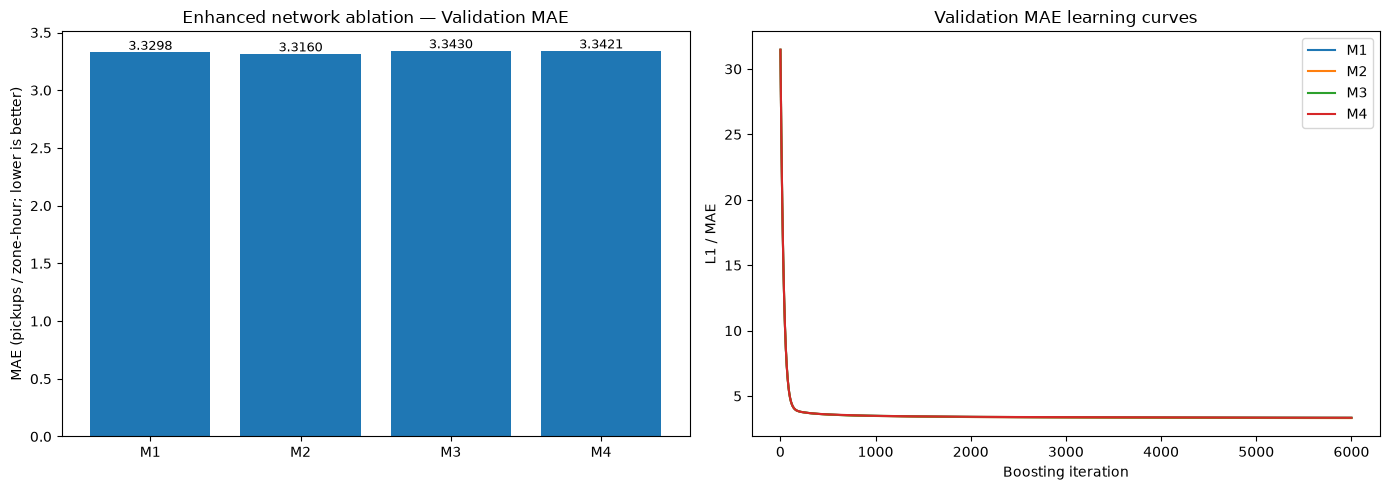

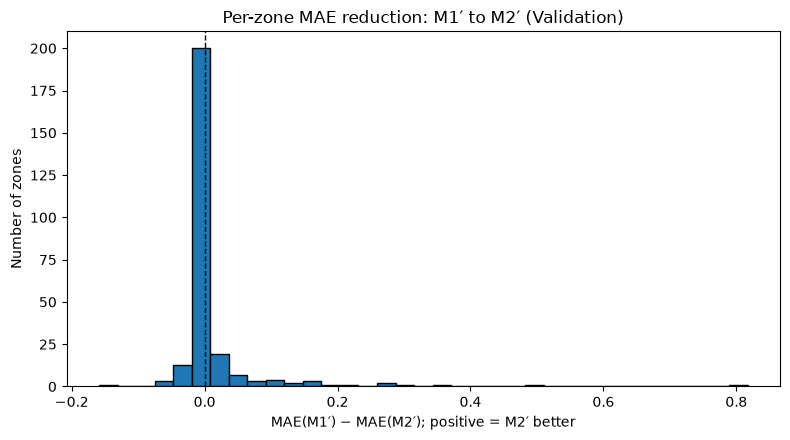


Top 12 gain-importance features: M2


,feature,gain_importance,split_importance
16,lag_168,9.314438e+08,16489
14,lag_1,6.386639e+07,15268
17,rolling_mean_24,1.601221e+07,3474
15,lag_24,8.308466e+06,13357
18,rolling_mean_168,5.758070e+06,6590
25,rolling_mean_3,4.110116e+06,5097
22,zone_id,3.495699e+06,46643
19,hour,3.051571e+06,17633
20,day_of_week,1.082516e+06,9335
29,out_strength_24h,6.748678e+05,2808



Top 12 gain-importance features: M3


,feature,gain_importance,split_importance
34,lag_168,9.314152e+08,15112
32,lag_1,6.414040e+07,14244
35,rolling_mean_24,1.583527e+07,2802
33,lag_24,8.290274e+06,12267
36,rolling_mean_168,5.701971e+06,5611
43,rolling_mean_3,4.012916e+06,4408
40,zone_id,3.485804e+06,45789
37,hour,3.057797e+06,17366
38,day_of_week,1.059010e+06,8692
47,out_strength_24h,6.511426e+05,2353



Top 12 gain-importance features: M4


,feature,gain_importance,split_importance
54,lag_168,9.304205e+08,14113
52,lag_1,6.411931e+07,13765
55,rolling_mean_24,1.691033e+07,2502
53,lag_24,8.248475e+06,11211
56,rolling_mean_168,5.479471e+06,5115
63,rolling_mean_3,4.201266e+06,4109
60,zone_id,3.465451e+06,45276
57,hour,3.004110e+06,17062
58,day_of_week,1.065064e+06,8402
67,out_strength_24h,6.423551e+05,2088


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
axes[0].bar(results_df["code"].str.upper(), results_df["val_mae"])
axes[0].set_title("Enhanced network ablation — Validation MAE")
axes[0].set_ylabel("MAE (pickups / zone-hour; lower is better)")
axes[0].set_ylim(bottom=0)
for i, v in enumerate(results_df["val_mae"]):
    axes[0].text(i, v + 0.02, f"{v:.4f}", ha="center", fontsize=9)

for code_name, hist in learning_histories.items():
    series = hist.get("valid_0", {}).get("l1", [])
    if not series:
        raise KeyError(f"Missing validation L1 learning history for {code_name}: {list(hist)}")
    axes[1].plot(np.arange(1, len(series)+1), series, label=code_name.upper())
axes[1].set_title("Validation MAE learning curves")
axes[1].set_xlabel("Boosting iteration")
axes[1].set_ylabel("L1 / MAE")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT / "enhanced_network_validation_and_curves.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8,4.5))
ax.hist(zone_table["gain_m1_to_m2"].to_numpy(), bins=35, edgecolor="black")
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_title("Per-zone MAE reduction: M1′ to M2′ (Validation)")
ax.set_xlabel("MAE(M1′) − MAE(M2′); positive = M2′ better")
ax.set_ylabel("Number of zones")
fig.tight_layout()
fig.savefig(OUT / "zone_gain_m1_to_m2_histogram.png", dpi=160, bbox_inches="tight")
plt.show()

for code_name in ["m2", "m3", "m4"]:
    sub = importance_df[importance_df["model"].str.startswith(code_name.upper())]
    print(f"\nTop 12 gain-importance features: {code_name.upper()}")
    display(sub.nlargest(12, "gain_importance")["feature gain_importance split_importance".split()])

## 11 — Save independent validation artifacts and manifest

All files go to `results/forecasting/enhanced_network_ablation/`; existing `final_rq3` models and test predictions are not modified. We save one row per validation zone-hour with consistent prediction columns so follow-up RQ4 work requires **no retraining**. Setting `SAVE_MODELS=True` saves individual fitted model files during training; default False avoids very large binary artifacts.

In [12]:
results_df.to_csv(OUT / "enhanced_network_model_comparison.csv", index=False)
monthly_df.to_csv(OUT / "validation_monthly_mae.csv", index=False)
zone_table.to_csv(OUT / "validation_per_zone_mae.csv", index=False)
bootstrap_df.to_csv(OUT / "validation_daily_block_bootstrap.csv", index=False)
importance_df.to_csv(OUT / "feature_importance.csv", index=False)
validation_predictions_df.to_parquet(OUT / "validation_predictions_m1_m4.parquet", index=False)

# Save learning histories as small JSON maps, keeping numeric entries JSON-serializable.
serialized_curves = {
    model: {dataset: {metric: [float(x) for x in values]
                      for metric, values in metric_map.items()}
            for dataset, metric_map in hist.items()}
    for model, hist in learning_histories.items()
}
(OUT / "validation_learning_curves.json").write_text(json.dumps(serialized_curves), encoding="utf-8")
manifest = {
    "notebook": "07_enhanced_network_ablation.ipynb",
    "purpose": "Enhanced temporal baseline and sequential OD network feature ablation; validation only",
    "data": {"clean_dir":str(CLEAN_DIR.relative_to(PROJECT_ROOT)),
             "network_file":str(AUG_FILE.relative_to(PROJECT_ROOT))},
    "splits": {"train_end_exclusive":str(TRAIN_END),"validation_end_exclusive":str(VAL_END),
               "train_rows":len(train),"validation_rows":len(val)},
    "smoke_test":SMOKE_TEST,
    "max_rounds":MAX_ROUNDS,
    "early_stopping_rounds":EARLY_STOPPING_ROUNDS,
    "params":COMMON_PARAMS,
    "feature_sets":FEATURE_SETS,
    "best_validation_model":str(results_df.sort_values("val_mae").iloc[0]["model"]),
    "numpy":np.__version__,"pandas":pd.__version__,"lightgbm":lgb.__version__,
    "python":platform.python_version(),
    "random_seed":RANDOM_SEED,
    "test_used_for_selection":False,
    "note":"Validation reused after notebook 06 selected temporal features; uncertainty is exploratory."
}
(OUT / "experiment_manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved artifacts to:", OUT)
for p in sorted(OUT.iterdir()):
    print(" -", p.name, f"({p.stat().st_size/1024:.1f} KiB)")
print("\nSummary (positive improvement means lower validation MAE):")
display(results_df[["model", "best_iteration", "near_round_cap", "val_mae", "val_rmse", "abs_mae_reduction_vs_previous", "rel_mae_reduction_vs_previous_pct"]].round(5))

Saved artifacts to: /Users/wushixundelaopo/Desktop/Urban_Mobility_Mining/results/forecasting/enhanced_network_ablation
 - enhanced_network_model_comparison.csv (0.9 KiB)
 - enhanced_network_validation_and_curves.png (72.2 KiB)
 - experiment_manifest.json (2.9 KiB)
 - feature_importance.csv (4.0 KiB)
 - validation_daily_block_bootstrap.csv (0.4 KiB)
 - validation_learning_curves.json (457.2 KiB)
 - validation_monthly_mae.csv (0.4 KiB)
 - validation_per_zone_mae.csv (43.5 KiB)
 - validation_predictions_m1_m4.parquet (36364.2 KiB)
 - zone_gain_m1_to_m2_histogram.png (38.0 KiB)

Summary (positive improvement means lower validation MAE):


,model,best_iteration,near_round_cap,val_mae,val_rmse,abs_mae_reduction_vs_previous,rel_mae_reduction_vs_previous_pct
0,M1 Enhanced Temporal,5998,True,3.32978,9.45644,NaN,NaN
1,M2 + OD Strength,6000,True,3.31604,9.37402,0.01374,0.41267
2,M3 + Degree,5997,True,3.34297,9.47219,-0.02693,-0.81210
3,M4 + HHI & Flow Flags,5999,True,3.34215,9.46551,0.00082,0.02441


## 12 —  Summary and Interpretation

### 12.1 Key Findings

This experiment evaluates whether historical OD network features improve hourly NYC Yellow Taxi pickup demand forecasting beyond an enhanced temporal baseline.

All models use the same training and validation samples, Poisson LightGBM configuration, and maximum of 6,000 boosting rounds.

| Model | Validation MAE | Validation RMSE |
|---|---:|---:|
| M1: Enhanced Temporal | 3.32978 | 9.45644 |
| **M2: + OD Strength** | **3.31604** | **9.37402** |
| M3: + Degree | 3.34297 | 9.47219 |
| M4: + HHI and Flow Flags | 3.34215 | 9.46551 |

**Finding 1 — Historical OD strength provides a modest improvement.**

Adding four historical OD strength features reduces validation MAE from 3.32978 to 3.31604, an improvement of approximately 0.413%. Validation RMSE also decreases from 9.45644 to 9.37402.

**Finding 2 — Additional network topology features do not improve overall forecasting accuracy.**

Adding degree increases validation MAE by 0.812% relative to M2. The subsequent addition of HHI and flow-availability indicators produces a negligible improvement of 0.024% over M3, but M4 still performs worse than M2.

Therefore, more complex structural summaries do not necessarily increase predictive accuracy.

**Finding 3 — Network improvement is observed in both validation months.**

M2 reduces MAE relative to M1 in September and October, with absolute improvements of approximately 0.01502 and 0.01250, respectively.

This provides evidence that the modest aggregate improvement is not driven exclusively by one validation month.

**Finding 4 — Network benefits are spatially heterogeneous.**

Only 99 of 263 taxi zones (37.6%) show lower MAE after adding OD Strength.

Nevertheless, overall validation MAE improves, indicating that improvements in some zones are sufficiently large to offset deteriorations elsewhere.

Several high-demand zones exhibit relatively large absolute MAE reductions. This motivates a more systematic investigation of whether network benefits are associated with historical demand volume.

**Finding 5 — The direction of the overall OD Strength improvement is stable under daily block resampling.**

A paired daily-block bootstrap with 2,000 resamples produces a 95% interval of approximately [0.00807, 0.01953] for the absolute MAE reduction from M1 to M2.

The corresponding interval for adding degree is negative, whereas the interval for adding HHI and flow flags includes zero.

These intervals provide exploratory uncertainty diagnostics rather than independent confirmatory inference.

**Finding 6 — Full model convergence remains uncertain.**

All four models reach their best validation iterations near the 6,000-round limit. The experiment therefore does not establish that the training process has fully converged.

### 12.2 Implications for Research Questions

**RQ3 — Do historical network features improve taxi demand forecasting?**

The results indicate that historical OD Strength provides modest additional predictive information beyond a stronger temporal baseline.

However, degree and HHI-related structural features do not improve overall validation accuracy under the evaluated configuration.

**RQ4 — Where and when are network features most useful?**

The network-related improvement is unevenly distributed across zones. The next step is to evaluate variation by training-defined demand level, time of day, weekday/weekend, and spatial location.

These analyses are developed in `08_forecasting_heterogeneity.ipynb`.

### 12.3 Limitations

- The forecasting task is rolling one-hour-ahead prediction, not a fixed multi-month forecast.
- The results describe NYC Yellow Taxi activity and should not be generalized directly to Uber, Lyft, or total urban transportation demand.
- Historical network features assume sufficiently prompt availability of completed-trip records.
- The local-time representation requires conservative exclusion of DST-affected observations.
- Models use a fixed parameter configuration and a 6,000-round training cap.
- Bootstrap results are exploratory because model selection and uncertainty assessment use the same validation period.
- The study evaluates historical network summaries rather than a full dynamic graph-based forecasting model.

### 12.4 Conclusion

**Historical OD Strength provides a modest but consistent improvement in validation forecasting accuracy beyond the enhanced temporal baseline. Additional connectivity and flow-concentration features do not improve overall performance under the evaluated model configuration.**
The improvement is spatially heterogeneous, motivating further analysis of the demand and temporal conditions under which network information is most useful.